[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S11/2_Practica/imagenet/S11_05_imagenet_mini_retos.ipynb)

# Mini-retos con fotos de ImageNet

**ImageNet** es la colección de fotos con la que se entrenaron muchas de las redes de visión más famosas: 1,2 millones de fotos reales en 1000 clases. Aquí usamos **Imagenette**, una selección de **10 clases de ImageNet** fáciles de distinguir, con fotos de verdad (no dibujadas): así se ve qué pasa con imágenes reales.

Cinco retos cortos, cada uno responde a **una sola pregunta**:

| Reto | Pregunta | Tarda |
|---|---|---|
| 1 | ¿Qué ve una red que ya conoce ImageNet? | ~1 min |
| 2 | ¿Qué logra una CNN que empieza de cero con pocas fotos? | ~1 min |
| 3 | ¿Y si reutiliza lo que ImageNet ya sabe? (*transfer learning*) | segundos |
| 4 | ¿Cuántas fotos hacen falta? | ~2 min |
| 5 | ¿Dónde se equivoca? | segundos |
| 6 | 🎁 Prueba con tu propia foto | segundos |

**Cómo se trabaja**
- ⚙️ **Se ejecuta tal cual** (pulsa ▶).
- ✏️ **Se toca un valor** y se vuelve a pulsar ▶ para ver qué cambia.
- Las celdas se ejecutan **de arriba abajo**. Si algo falla, *Entorno de ejecución → Reiniciar y ejecutar todo*.
- No hace falta GPU. Hace falta internet (descarga ~100 MB una vez).

### ⚙️ Preparación — pulsa ▶

In [1]:
import os, time, tarfile, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from tensorflow import keras
from tensorflow.keras.applications import mobilenet_v2

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
rng = np.random.default_rng(SEMILLA)
print("Listo ✔")

Listo ✔


### ⚙️ Descargar las fotos — pulsa ▶

Imagenette viene en una carpeta por clase (la **carpeta es la etiqueta**, como en el reto S11_04). Cada carpeta se llama con el código de ImageNet (`n01440764`…); abajo los traducimos.

In [2]:
URL = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz"   # copia de 160 px de lado (~100 MB)
archivo = keras.utils.get_file("imagenette2-160.tgz", URL)
if not os.path.isdir("imagenette"):
    with tarfile.open(archivo) as t:
        t.extractall("imagenette")
RAIZ = "imagenette/imagenette2-160"

NOMBRES = {  # código ImageNet -> nombre en español
    "n01440764": "tenca (pez)", "n02102040": "perro springer", "n02979186": "radiocasete",
    "n03000684": "motosierra", "n03028079": "iglesia", "n03394916": "trompa (instrumento)",
    "n03417042": "camión de basura", "n03425413": "surtidor", "n03445777": "pelota de golf",
    "n03888257": "paracaídas"}
CODIGOS = sorted(NOMBRES)
CLASES = [NOMBRES[c] for c in CODIGOS]

filas = [(NOMBRES[c], len(os.listdir(f"{RAIZ}/train/{c}")), len(os.listdir(f"{RAIZ}/val/{c}"))) for c in CODIGOS]
display(pd.DataFrame(filas, columns=["clase", "fotos de entrenamiento", "fotos de prueba"]))

99003388/99003388 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


/tmp/ipykernel_1422/3728987772.py:5: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall("imagenette")


,clase,fotos de entrenamiento,fotos de prueba
0,tenca (pez),963,387
1,perro springer,955,395
2,radiocasete,993,357
3,motosierra,858,386
4,iglesia,941,409
5,trompa (instrumento),956,394
6,camión de basura,961,389
7,surtidor,931,419
8,pelota de golf,951,399
9,paracaídas,960,390


### ⚙️ Cargar las fotos en la memoria — pulsa ▶

Se reparten en **tres grupos** (como siempre): **entrenamiento** (la red aprende; hasta 200 por clase), **validación** (30 por clase, para comparar y elegir) y **prueba** (50 por clase, se mira **una sola vez, al final**).

Cada foto se recorta a cuadrado y se reduce a **96×96 píxeles** para que todo sea rápido.

entrenamiento: (10, 200, 96, 96, 3) · validación: (10, 30, 96, 96, 3) · prueba: (10, 50, 96, 96, 3) · 4 s


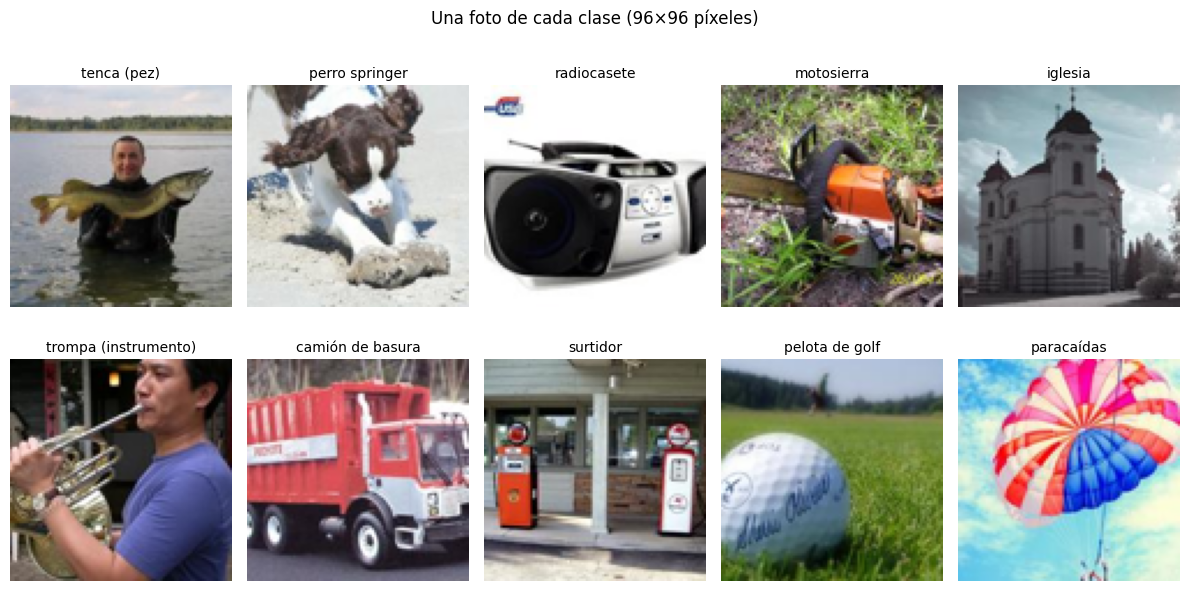

In [3]:
TAM = 96

def abrir(ruta, tam):
    """Abre una foto, la recorta a cuadrado por el centro y la reduce a tam×tam."""
    im = Image.open(ruta).convert("RGB")
    w, h = im.size; l = min(w, h)
    im = im.crop(((w - l) // 2, (h - l) // 2, (w - l) // 2 + l, (h - l) // 2 + l)).resize((tam, tam))
    return np.asarray(im, dtype="uint8")

def cargar(carpeta, desde, hasta, tam):
    """Devuelve un array (clases, fotos por clase, tam, tam, 3) con las fotos desde..hasta de cada clase."""
    por_clase = []
    for c in CODIGOS:
        ficheros = sorted(os.listdir(f"{RAIZ}/{carpeta}/{c}"))
        np.random.default_rng(SEMILLA).shuffle(ficheros)          # mismo orden en cada ejecución
        por_clase.append([abrir(f"{RAIZ}/{carpeta}/{c}/{f}", tam) for f in ficheros[desde:hasta]])
    return np.array(por_clase)

t0 = time.time()
X_ent = cargar("train", 0, 200, TAM)        # (10, 200, 96, 96, 3)
X_val = cargar("train", 200, 230, TAM)      # (10, 30, 96, 96, 3)  fotos distintas de las de entrenamiento
X_pru = cargar("val", 0, 50, TAM)           # (10, 50, 96, 96, 3)
print("entrenamiento:", X_ent.shape, "· validación:", X_val.shape, "· prueba:", X_pru.shape, f"· {time.time()-t0:.0f} s")

def aplanar(X):
    """(clases, n, ...) -> (clases*n, ...) y sus etiquetas 0..9."""
    return X.reshape(-1, *X.shape[2:]), np.repeat(np.arange(len(CODIGOS)), X.shape[1])

fig, ejes = plt.subplots(2, 5, figsize=(12, 6.4))
for i, ax in enumerate(ejes.ravel()):
    ax.imshow(X_ent[i, 0]); ax.set_title(CLASES[i], fontsize=10); ax.axis("off")
plt.suptitle("Una foto de cada clase (96×96 píxeles)"); plt.tight_layout(); plt.show()

## 🔎 Reto 1 · ¿Qué ve una red que ya conoce ImageNet?

**MobileNetV2** es una CNN pequeña que ya vino **entrenada con ImageNet** (1000 clases). No la entrenamos: solo le enseñamos fotos y miramos qué dice. Devuelve una **probabilidad por cada una de las 1000 clases**; mostramos las 3 más probables.

In [4]:
# Descarga la red (≈14 MB) y la lista de las 1000 clases
red_imagenet = mobilenet_v2.MobileNetV2(weights="imagenet")          # entrada 224×224, salida 1000 clases
indice = json.load(open(keras.utils.get_file("imagenet_class_index.json",
         "https://storage.googleapis.com/download.tensorflow.org/data/imagenet_class_index.json")))
NOMBRE_IMAGENET = {int(k): v[1] for k, v in indice.items()}           # 0..999 -> nombre en inglés
INDICE_DE = {v[0]: int(k) for k, v in indice.items()}                  # código n01440764 -> 0
INDICES_10 = [INDICE_DE[c] for c in CODIGOS]                           # sus posiciones entre las 1000
print("Clases de ImageNet:", len(NOMBRE_IMAGENET), "· nuestras 10 clases son las posiciones", INDICES_10)

X224 = cargar("val", 0, 50, 224)                                        # las mismas 50 fotos de prueba, a 224 px
X224, y_pru = aplanar(X224)
prob1000 = red_imagenet.predict(mobilenet_v2.preprocess_input(X224.astype("float32")), batch_size=50, verbose=0)
print("Listo ✔")

14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Clases de ImageNet: 1000 · nuestras 10 clases son las posiciones [0, 217, 482, 491, 497, 566, 569, 571, 574, 701]
Listo ✔


### ✏️ 1 · Elige una foto y pregúntale a la red

Cambia **FOTO** (de 0 a 499) y pulsa ▶. Las fotos están ordenadas por clase: 0–49 tenca, 50–99 springer… Prueba varias, sobre todo de clases distintas.

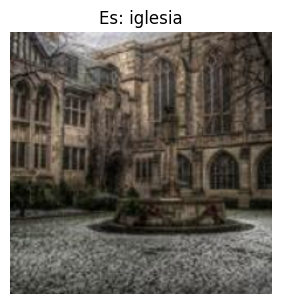

 22.6 %  monastery
  7.0 %  palace
  4.6 %  vault


In [9]:
FOTO = 200          # ✏️ número de foto, de 0 a 499

top3 = np.argsort(-prob1000[FOTO])[:3]
plt.figure(figsize=(3.4, 3.4)); plt.imshow(X224[FOTO]); plt.axis("off")
plt.title(f"Es: {CLASES[y_pru[FOTO]]}"); plt.show()
for k in top3:
    print(f"{prob1000[FOTO, k]*100:5.1f} %  {NOMBRE_IMAGENET[k]}")

### ⚙️ ¿Acierta esta red en las 500 fotos de prueba? — pulsa ▶

Las 10 clases de Imagenette **son** clases de ImageNet, así que podemos comprobar si la clase que la red pone en **primer lugar** es la correcta.

In [10]:
pred1000 = prob1000.argmax(axis=1)
acierta = pred1000 == np.array(INDICES_10)[y_pru]
tabla = pd.DataFrame({"clase": CLASES, "acierto": [round(acierta[y_pru == i].mean(), 2) for i in range(10)]})
display(tabla)
print(f"Acierto total de la red de ImageNet (eligiendo entre 1000 clases): {acierta.mean():.3f}")

,clase,acierto
0,tenca (pez),0.96
1,perro springer,0.58
2,radiocasete,0.72
3,motosierra,0.74
4,iglesia,0.20
5,trompa (instrumento),0.78
6,camión de basura,0.72
7,surtidor,0.64
8,pelota de golf,0.92
9,paracaídas,0.78


Acierto total de la red de ImageNet (eligiendo entre 1000 clases): 0.704


**Qué significa dentro de la red:** la capa final tiene **1000 neuronas de salida**, una por clase, y la de mayor probabilidad es la respuesta. Esta red ya «sabe ver» porque sus capas convolucionales aprendieron bordes, texturas y formas con millones de fotos.

🔴 **Mini-reto:** ¿qué clases acierta menos? Escribe una hipótesis de por qué (¿se parece a otra clase de ImageNet que no está entre las 10?).

# **MI HIPÓTESIS**

La clase que peor reconoce es la iglesia, con solo un 20 % de aciertos. También tiene dificultades con el perro springer (58 %) y el surtidor (64 %). Creemos que se debe a que algunas imágenes tienen formas y características similares a otras categorías de ImageNet, por lo que la red puede confundirlas.

Conclusión: la red reconoce muy bien algunas clases, como la tenca (96 %) y la pelota de golf (92 %), pero tiene dificultades con otras. Esto demuestra que no todas las categorías se identifican con la misma precisión.

## 🧱 Reto 2 · Una CNN que empieza de cero, con pocas fotos

Ahora **no** usamos lo que ImageNet sabe: entrenamos una CNN pequeña con pesos al azar, con **pocas fotos por clase**. Es lo que pasa en un proyecto real cuando solo hay unas decenas de fotos.

La red: 3 bloques de **convolución + pooling** (buscan bordes, luego formas) y unas pocas neuronas densas al final.

In [11]:
def construir_cnn(aumento=False):
    capas = [keras.layers.Input(shape=(TAM, TAM, 3))]
    if aumento:   # ver cada foto un poco movida y a veces girada: parece más variedad
        capas += [keras.layers.RandomFlip("horizontal"), keras.layers.RandomTranslation(0.1, 0.1)]
    capas += [keras.layers.Rescaling(1 / 255)]                        # píxeles de 0-255 a 0-1
    for filtros in (16, 32, 64):
        capas += [keras.layers.Conv2D(filtros, 3, padding="same", activation="relu"), keras.layers.MaxPooling2D()]
    capas += [keras.layers.GlobalAveragePooling2D(), keras.layers.Dense(64, activation="relu"),
              keras.layers.Dense(10, activation="softmax")]
    m = keras.Sequential(capas)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def entrenar_cnn(n, aumento=False, epocas=25):
    keras.utils.set_random_seed(SEMILLA)
    X, y = aplanar(X_ent[:, :n]); Xv, yv = aplanar(X_val)
    m = construir_cnn(aumento)
    parada = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True, monitor="val_accuracy")
    h = m.fit(X, y, validation_data=(Xv, yv), epochs=epocas, batch_size=32, callbacks=[parada], verbose=0)
    return m, h

construir_cnn().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,394 (110.91 KB)

 Trainable params: 28,394 (110.91 KB)

 Non-trainable params: 0 (0.00 B)

### ✏️ 2 · Entrena con pocas fotos

Cambia **FOTOS_POR_CLASE** (entre 5 y 200) y pulsa ▶. Mira la **exactitud en validación** (de 0 a 1; el azar con 10 clases sería 0.10). Extra 🔴: pon `AUMENTO = True` y compara.

CNN desde cero con 400 fotos → exactitud en validación: 0.350  (25 épocas, 28,394 parámetros, 118 s)


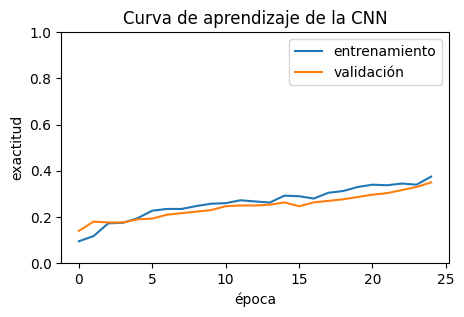

In [14]:
FOTOS_POR_CLASE = 40      # ✏️ entre 5 y 200
AUMENTO = False           # ✏️ True = la red ve cada foto movida/girada

t0 = time.time()
cnn, h = entrenar_cnn(FOTOS_POR_CLASE, AUMENTO)
val_cnn = max(h.history["val_accuracy"])
print(f"CNN desde cero con {FOTOS_POR_CLASE*10} fotos → exactitud en validación: {val_cnn:.3f}  "
      f"({len(h.history['loss'])} épocas, {cnn.count_params():,} parámetros, {time.time()-t0:.0f} s)")

plt.figure(figsize=(5, 3)); plt.plot(h.history["accuracy"], label="entrenamiento"); plt.plot(h.history["val_accuracy"], label="validación")
plt.xlabel("época"); plt.ylabel("exactitud"); plt.ylim(0, 1); plt.legend(); plt.title("Curva de aprendizaje de la CNN"); plt.show()

**Qué significa dentro de la red:** con pocas fotos, los **filtros de las convoluciones** (que empiezan siendo ruido) no llegan a aprender patrones útiles. Si la curva de entrenamiento sube y la de validación no, la red **memoriza** las fotos en vez de aprender a reconocer.

## ♻️ Reto 3 · Reutilizar lo que ImageNet ya sabe (*transfer learning*)

Cogemos **MobileNetV2 sin su última capa** (la de las 1000 clases) y la **congelamos**: sus pesos no cambian. Solo entrenamos una **capa nueva de 10 neuronas** (una por nuestra clase) encima.

Truco para que sea rápido: como la parte congelada **siempre da la misma salida para la misma foto**, la calculamos **una sola vez** (un vector de 1280 números por foto) y entrenamos solo la capa nueva con esos vectores. El resultado es el mismo que entrenar la red completa congelada, pero en segundos.

In [15]:
extractor = mobilenet_v2.MobileNetV2(input_shape=(TAM, TAM, 3), include_top=False, weights="imagenet", pooling="avg")
extractor.trainable = False
print("Parte congelada:", f"{extractor.count_params():,} parámetros, salida de", extractor.output_shape[-1], "números por foto")

def vectores(X):
    """(clases, n, 96, 96, 3) -> (clases, n, 1280): lo que «ve» la parte congelada en cada foto."""
    plano = mobilenet_v2.preprocess_input(X.reshape(-1, TAM, TAM, 3).astype("float32"))
    return extractor.predict(plano, batch_size=64, verbose=0).reshape(*X.shape[:2], -1)

t0 = time.time()
V_ent, V_val, V_pru = vectores(X_ent), vectores(X_val), vectores(X_pru)
print(f"Vectores calculados: {V_ent.shape} · {time.time()-t0:.0f} s")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Parte congelada: 2,257,984 parámetros, salida de 1280 números por foto
Vectores calculados: (10, 200, 1280) · 21 s


In [16]:
def entrenar_cabeza(n, epocas=60):
    keras.utils.set_random_seed(SEMILLA)
    V, y = aplanar(V_ent[:, :n]); Vv, yv = aplanar(V_val)
    m = keras.Sequential([keras.layers.Input(shape=(V.shape[1],)), keras.layers.Dense(10, activation="softmax")])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    parada = keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True, monitor="val_accuracy")
    h = m.fit(V, y, validation_data=(Vv, yv), epochs=epocas, batch_size=32, callbacks=[parada], verbose=0)
    return m, h
print("Listo ✔")

Listo ✔


### ✏️ 3 · Compara con la CNN del reto 2

Usa **las mismas fotos** (`FOTOS_POR_CLASE`) para que la comparación sea justa. Pulsa ▶.

In [17]:
cabeza, h3 = entrenar_cabeza(FOTOS_POR_CLASE)
val_tl = max(h3.history["val_accuracy"])
display(pd.DataFrame({
    "modelo": ["CNN desde cero", "ImageNet congelada + capa nueva"],
    "fotos": [FOTOS_POR_CLASE * 10] * 2,
    "parámetros que se entrenan": [cnn.count_params(), cabeza.count_params()],
    "exactitud en validación": [round(val_cnn, 3), round(val_tl, 3)]}))

,modelo,fotos,parámetros que se entrenan,exactitud en validación
0,CNN desde cero,400,28394,0.350
1,ImageNet congelada + capa nueva,400,12810,0.917


**Qué significa dentro de la red:** la parte congelada ya convierte cada foto en 1280 números que **describen lo que hay** (formas, texturas, partes de objetos). La capa nueva solo aprende **cuánto pesa cada número** para cada clase: son `1280 × 10 + 10` pesos, no millones. Por eso aprende con pocas fotos.

## 📈 Reto 4 · ¿Cuántas fotos hacen falta?

Entrenamos las dos opciones con cada cantidad de fotos por clase y dibujamos la **exactitud en validación**. Tarda un par de minutos (la CNN es la parte lenta).

### ✏️ 4 · Elige las cantidades

Cambia **LISTA_N** (valores entre 2 y 200) y pulsa ▶. Con menos valores va más rápido.

5 fotos por clase ✔  10 fotos por clase ✔  25 fotos por clase ✔  50 fotos por clase ✔  100 fotos por clase ✔  


,fotos_por_clase,cnn_desde_cero,transfer_learning
0,5,0.207,0.837
1,10,0.177,0.853
2,25,0.200,0.923
3,50,0.357,0.930
4,100,0.333,0.930


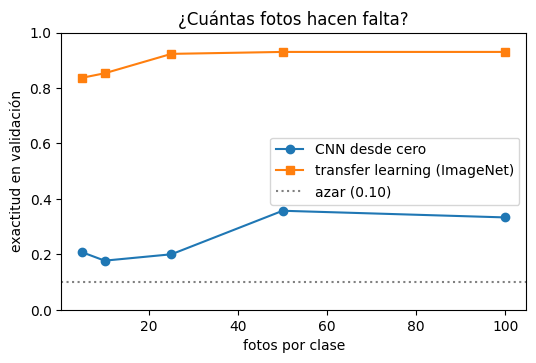

In [18]:
LISTA_N = [5, 10, 25, 50, 100]      # ✏️ fotos por clase que se prueban

res = []
for n in LISTA_N:
    _, hc = entrenar_cnn(n, AUMENTO)
    _, ht = entrenar_cabeza(n)
    res.append(dict(fotos_por_clase=n, cnn_desde_cero=round(max(hc.history["val_accuracy"]), 3),
                    transfer_learning=round(max(ht.history["val_accuracy"]), 3)))
    print(f"{n} fotos por clase ✔", end="  ")
curva = pd.DataFrame(res); print(); display(curva)

plt.figure(figsize=(6, 3.6))
plt.plot(curva.fotos_por_clase, curva.cnn_desde_cero, "o-", label="CNN desde cero")
plt.plot(curva.fotos_por_clase, curva.transfer_learning, "s-", label="transfer learning (ImageNet)")
plt.axhline(0.1, color="gray", ls=":", label="azar (0.10)")
plt.xlabel("fotos por clase"); plt.ylabel("exactitud en validación"); plt.ylim(0, 1)
plt.title("¿Cuántas fotos hacen falta?"); plt.legend(); plt.show()

- Con 5 fotos, Transfer Learning consigue un 83,7 %, mientras que la CNN desde cero solo alcanza un 20,7 %.
- Con 25 fotos, Transfer Learning llega al 92,3 %.
- Con 50 fotos, la CNN desde cero mejora hasta el 35,7 %.
- Con 100 fotos, Transfer Learning mantiene un 93 % de precisión.

¿Cuál es mejor?

Ganador: Transfer Learning
Transfer Learning obtiene mejores resultados en todas las pruebas. Esto ocurre porque aprovecha características que ya había aprendido anteriormente, como bordes, formas y texturas.

La CNN desde cero necesita muchas más fotografías y entrenamiento para aprender esas características.

Transfer Learning funciona mucho mejor que la CNN desde cero, incluso utilizando pocas fotografías. Con solo 25 fotos por clase consigue un 92,3 % de precisión, mientras que la CNN desde cero no supera el 35,7 % ni siquiera con 50 fotos. Esto demuestra que aprovechar un modelo previamente entrenado permite obtener mejores resultados con menos datos y menos tiempo de entrenamiento.

🔴 **Mini-reto:** ¿cuántas fotos por clase necesita la CNN desde cero para igualar lo que el transfer learning logra con **5**? Escribe tu estimación mirando la gráfica.

In [ ]:
MI_ESTIMACION = ""        # ✏️ tu respuesta

El Transfer Learning consigue un 83,7 % con solo 5 fotos por clase.

La CNN desde cero alcanza únicamente un 35,7 % con 50 fotos. Por tanto, necesitaría bastantes más fotografías para igualarlo.

**Estimación:**

La CNN desde cero podría necesitar aproximadamente entre 500 y 1.000 fotos por clase para acercarse al 83,7 %, aunque habría que comprobarlo experimentalmente.

Conclusión: Transfer Learning necesita muchas menos imágenes porque ya tiene conocimientos aprendidos de entrenamientos anteriores.

## 🔍 Reto 5 · ¿Dónde se equivoca?

Ahora sí: probamos el modelo de transfer learning con las **500 fotos de prueba**, que no ha visto nunca ni se han usado para decidir nada. Miramos la **matriz de confusión** (fila = clase real, columna = lo que dijo la red) y las fotos mal clasificadas.

Exactitud en prueba (500 fotos): 0.950


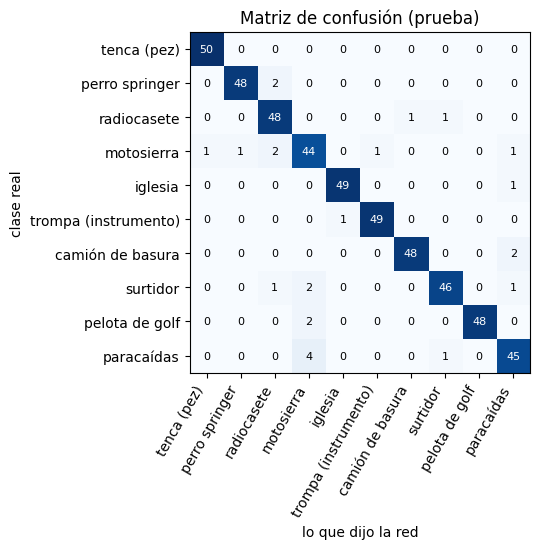

In [19]:
cabeza, _ = entrenar_cabeza(200)                       # con todas las fotos de entrenamiento
Vp, yp = aplanar(V_pru)
prob = cabeza.predict(Vp, verbose=0); pred = prob.argmax(axis=1)
print(f"Exactitud en prueba (500 fotos): {(pred == yp).mean():.3f}")

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(yp, pred)
plt.figure(figsize=(6.4, 5.6)); plt.imshow(cm, cmap="Blues")
plt.xticks(range(10), CLASES, rotation=60, ha="right"); plt.yticks(range(10), CLASES)
for i in range(10):
    for j in range(10): plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.xlabel("lo que dijo la red"); plt.ylabel("clase real"); plt.title("Matriz de confusión (prueba)"); plt.tight_layout(); plt.show()

### ⚙️ Las fotos mal clasificadas — pulsa ▶

Se muestran las equivocaciones **más seguras** (la red estaba muy convencida y falló).

25 errores de 500. Los 10 más seguros:


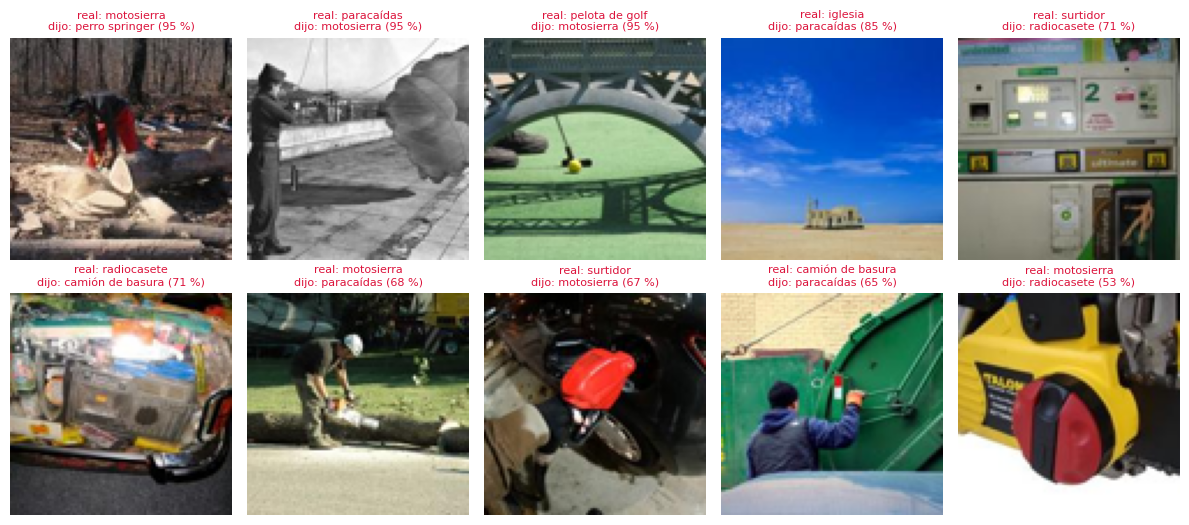

In [20]:
Xp, _ = aplanar(X_pru)
errores = np.where(pred != yp)[0]
errores = errores[np.argsort(-prob.max(axis=1)[errores])][:10]
print(f"{(pred != yp).sum()} errores de 500. Los 10 más seguros:")
fig, ejes = plt.subplots(2, 5, figsize=(12, 5.4))
for ax, k in zip(ejes.ravel(), errores):
    ax.imshow(Xp[k]); ax.axis("off")
    ax.set_title(f"real: {CLASES[yp[k]]}\ndijo: {CLASES[pred[k]]} ({prob[k].max()*100:.0f} %)", fontsize=8, color="crimson")
plt.tight_layout(); plt.show()

**Qué significa dentro de la red:** las 10 neuronas de salida dan una probabilidad cada una y gana la mayor. Un error «muy seguro» indica que **para esa foto los 1280 números se parecen más a otra clase**: o la foto es ambigua, o falta variedad en los datos de esa clase.

🔴 **Mini-reto:** mira la matriz de confusión y escribe qué par de clases se confunde más y por qué crees que pasa.

# **MI CONCLUSIÓN:**

Las clases que más se confunden son paracaídas y motosierra. La red confunde especialmente los paracaídas con motosierras. Creemos que ocurre porque algunas imágenes pueden tener características visuales ambiguas o fondos que dificultan reconocer correctamente el objeto.

Dato importante: el modelo consigue un 95 % de exactitud en las 500 fotografías de prueba, por lo que su rendimiento general es bastante bueno.

## 🎁 Reto 6 · Prueba con tu propia foto

Sube una foto tuya (o pega la dirección de una imagen) y mira qué dicen **dos redes**: la tuya, que solo conoce **10 clases**, y la de ImageNet, que conoce **1000**.

⚠️ Tu modelo **siempre elige una de sus 10 clases**, aunque la foto no tenga nada que ver (una foto de un gato la llamará «perro springer»). Es un límite importante de estas redes.

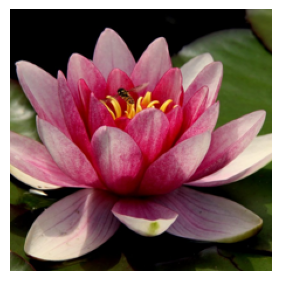

f51f Tu modelo (10 clases):
    25.8 %  pelota de golf
    21.1 %  camión de basura
    19.5 %  paracaídas
f310 Red de ImageNet (1000 clases):
    80.1 %  daisy
     6.9 %  pot
     3.0 %  bee


In [24]:
URL_FOTO = ""      # ✏️ opción A: dirección web de una imagen (termina en .jpg o .png)
RUTA_FOTO = "/content/flor-de-loto-e1653918982491.jpg"     # ✏️ opción B: ruta de un archivo ya subido a Colab. Si dejas A y B vacías, Colab abre el selector de archivos.

def conseguir_foto():
    if URL_FOTO:
        import urllib.request
        pet = urllib.request.Request(URL_FOTO, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(pet) as r, open("mi_foto", "wb") as f: f.write(r.read())
        return "mi_foto"
    if RUTA_FOTO: return RUTA_FOTO
    try:
        from google.colab import files
    except ImportError:
        print("Fuera de Colab: escribe la ruta de una imagen en RUTA_FOTO"); return None
    subidos = files.upload()
    if subidos:
        return list(subidos.keys())[0]
    return None

ruta = conseguir_foto()
if ruta:
    mia96, mia224 = abrir(ruta, TAM), abrir(ruta, 224)
    p10 = cabeza.predict(vectores(mia96[None, None]).reshape(1, -1), verbose=0)[0]
    p1000 = red_imagenet.predict(mobilenet_v2.preprocess_input(mia224[None].astype("float32")), verbose=0)[0]
    plt.figure(figsize=(3.4, 3.4)); plt.imshow(mia224); plt.axis("off"); plt.show()
    print("f51f Tu modelo (10 clases):")
    for k in np.argsort(-p10)[:3]: print(f"   {p10[k]*100:5.1f} %  {CLASES[k]}")
    print("f310 Red de ImageNet (1000 clases):")
    for k in np.argsort(-p1000)[:3]: print(f"   {p1000[k]*100:5.1f} %  {NOMBRE_IMAGENET[k]}")

## 🧾 Ficha final — pulsa ▶

Resume lo que has medido. Los números salen de lo que has ejecutado arriba.

In [27]:
# Definimos tus respuestas escritas en las celdas de texto como variables de Python:
MI_HIPOTESIS = "La iglesia es la que peor se reconoce debido a la ambigüedad con categorías similares de ImageNet."
MI_ESTIMACION = "Entre 500 y 1.000 fotos por clase."
MI_CONCLUSION = "Las clases que más se confunden son paracaídas y motosierra por ambigüedad visual, logrando un 95% de exactitud general."

test_tl = (pred == yp).mean()
display(pd.DataFrame([
    ("Red de ImageNet, 1000 clases (reto 1)", "prueba", round(acierta.mean(), 3)),
    (f"CNN desde cero, {FOTOS_POR_CLASE*10} fotos (reto 2)", "validación", round(val_cnn, 3)),
    (f"Transfer learning, {FOTOS_POR_CLASE*10} fotos (reto 3)", "validación", round(val_tl, 3)),
    ("Transfer learning, 2000 fotos (reto 5)", "prueba", round(test_tl, 3))],
    columns=["modelo", "dónde se mide", "exactitud"]))
print("Tus conclusiones:\n · reto 1:", MI_HIPOTESIS or "—", "\n · reto 4:", MI_ESTIMACION or "—", "\n · reto 5:", MI_CONCLUSION or "—")

,modelo,dónde se mide,exactitud
0,"Red de ImageNet, 1000 clases (reto 1)",prueba,0.704
1,"CNN desde cero, 400 fotos (reto 2)",validación,0.350
2,"Transfer learning, 400 fotos (reto 3)",validación,0.917
3,"Transfer learning, 2000 fotos (reto 5)",prueba,0.950


Tus conclusiones:
 · reto 1: La iglesia es la que peor se reconoce debido a la ambigüedad con categorías similares de ImageNet. 
 · reto 4: Entre 500 y 1.000 fotos por clase. 
 · reto 5: Las clases que más se confunden son paracaídas y motosierra por ambigüedad visual, logrando un 95% de exactitud general.


### 🔴 Para ir más lejos
- Cambia `TAM` a 128 y vuelve a ejecutar desde la carga de fotos: ¿mejora? ¿cuánto tarda más?
- En el reto 3, descongela las últimas capas de MobileNetV2 (*fine-tuning*, como en S11_02): ¿mejora la prueba?
- Imagenette tiene variantes: **Imagewoof** (10 razas de perro, mucho más difícil). ¿Aguanta el mismo método?